Aiyanna Ranch: Likes Report 9/20/2026
I downloaded this data and Instagram created this data.
This data was created to organize and analyze my liked posts information. The data can be used to allow Instagram to keep track of my activity and potentially personalize my experience on the platform. The data can also be used to analyze my own social media behavior. The data can be reliable because it comes directly from my Instagram activity and records posts I actually liked. The data can be unreliable because it only shows my Instagram likes and may not represent all of my interests or social-media activity.

In [20]:
import json
import pandas as pd

with open('liked_posts2.json', 'r') as f:
    data = json.load(f)

data[0]

{'timestamp': 1788106321,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/p/Dccmk1SFjPl/',
   'href': 'https://www.instagram.com/p/Dccmk1SFjPl/'},
  {'dict': [], 'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL', 'value': ''},
      {'label': 'Name', 'value': 'mymy'},
      {'label': 'Username', 'value': 'dollsburner'}],
     'title': ''}],
   'title': 'Owner'},
  {'dict': [], 'title': 'Brand partner'}],
 'fbid': '18412216504154818'}

In [21]:
row = {}
row['timestamp'] = data[0]['timestamp']

row

{'timestamp': 1788106321}

In [22]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']

row

{'timestamp': 1788106321, 'URL': 'https://www.instagram.com/p/Dccmk1SFjPl/'}

In [23]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner': 
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['Owner' + owner_item['label']]= owner_item['value']
       
        

row

{'timestamp': 1788106321,
 'URL': 'https://www.instagram.com/p/Dccmk1SFjPl/',
 'OwnerURL': '',
 'OwnerName': 'mymy',
 'OwnerUsername': 'dollsburner'}

In [24]:
tidy_rows = []

for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']

    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['Owner' + owner_item['label']]= owner_item['value']
    tidy_rows.append(row)

tidy_rows[:2]

[{'timestamp': 1788106321,
  'URL': 'https://www.instagram.com/p/Dccmk1SFjPl/',
  'OwnerURL': '',
  'OwnerName': 'mymy',
  'OwnerUsername': 'dollsburner'},
 {'timestamp': 1788106185,
  'URL': 'https://www.instagram.com/p/DcW5cNzlAwA/',
  'Caption': 'H22ð\x9f\x90¬ð\x9f«§ð\x9f§\x9cð\x9f\x8f½â\x80\x8dâ\x99\x80ï¸\x8fð\x9f\x8e\x80',
  'Title': '',
  'OwnerURL': 'https://www.tiktok.com/@mrssesco',
  'OwnerName': '',
  'OwnerUsername': 'madamemercedess'}]

In [25]:
likes_df = pd.DataFrame(tidy_rows)
likes_df.head(10)

,timestamp,URL,OwnerURL,OwnerName,OwnerUsername,Caption,Title
0,1788106321,https://www.instagram.com/p/Dccmk1SFjPl/,,mymy,dollsburner,NaN,NaN
1,1788106185,https://www.instagram.com/p/DcW5cNzlAwA/,https://www.tiktok.com/@mrssesco,,madamemercedess,H22ð¬ð«§ð§ð½ââï¸ð,
2,1788103396,https://www.instagram.com/p/Db-4DAflO6N/,,Why you should have an animal,youronlysourceofserotonin_,Cheetah cubs are tiny bundles of energy! ðð...,
3,1788067466,https://www.instagram.com/p/DcZVv6UNJmU/,https://www.pizzabaconcourses.com/course,pizzabacon,_pizzabacon,SORRY FOR THE DOUBLE MH DROP i was on a plane ...,
4,1788067435,https://www.instagram.com/p/DckRv-8jljfQ_OOzUk...,,youwillrememberme,iamjustdavi_,oww!!\n\nBOO!!\n\nhm?ð«ª\n\niâve just been ...,
5,1787251935,https://www.instagram.com/p/DcPApS5t-wH/,,,sarcaqsm,follow ( @sarcaqsm ) for more!\nâ¢\nTam adi G...,
6,1787251899,https://www.instagram.com/p/DcPSmfgoE87/,,DM FOR PROMO,fkfeelings_1,Jaapani uue pÃµlvkonna futuristliku trapâi j...,
7,1787232833,https://www.instagram.com/p/DcOZieKQleZ/,,Memes | Comedy | Entertainment,mythicalmemevault,RYONEX DHE VALA E RE E TRAP-IT JAPONEZ\n\nNÃ« ...,
8,1787232716,https://www.instagram.com/reel/DYgHMXusTzI/,https://linktr.ee/ErvoTv,Erv Â³,ervotv,Camonðð¹\n#explore #funny #relatable #904...,
9,1787232600,https://www.instagram.com/p/DcOffldOgJc/,https://youtube.com/@wesogeeked?si=U-I-eAQwAaV...,,wesoogeeked,NaN,NaN


In [26]:
likes_df['DateTime'] = pd.to_datetime(likes_df['timestamp'], unit='s')
likes_df[['timestamp', 'DateTime']].head()

,timestamp,DateTime
0,1788106321,2026-08-30 16:12:01
1,1788106185,2026-08-30 16:09:45
2,1788103396,2026-08-30 15:23:16
3,1788067466,2026-08-30 05:24:26
4,1788067435,2026-08-30 05:23:55


In [27]:
likes_df.shape

(5739, 8)

In [28]:
likes_df['OwnerUsername'].isna().sum()

np.int64(0)

In [73]:
likes_df.dtypes

timestamp                int64
URL                        str
OwnerURL                   str
OwnerName                  str
OwnerUsername              str
Caption                    str
Title                      str
DateTime         datetime64[s]
dtype: object

In [74]:
likes_df.groupby("OwnerUsername")["DateTime"].count()

OwnerUsername
05.29.sr            1
0fficial.najaaa     1
0nly1mssperfectt    1
0nlyherway          1
0so.ke              1
                   ..
zosterday           2
zosttgames          1
zosttposts          1
zuckubus            1
zxenalynn           1
Name: DateTime, Length: 4532, dtype: int64

In [31]:
likes_by_account = (
    likes_df.groupby("OwnerUsername")["DateTime"]
    .count()
    .sort_values(ascending=False)
)
likes_by_account.head(10)

OwnerUsername
_pizzabacon          48
lov3charlee          39
darnasiadawson       34
nanasfinstta         26
love4infiny          19
nailsbyjasminerae    17
joy_mechell          17
pophistorybook       16
kentstate            16
beingblackislit      14
Name: DateTime, dtype: int64

A hypothesis that could be tested using some of my personal Instagram would be that the people whose post I've liked the most in my following list, are also the people I have followed the longest. The theoretical elements of my hypothesis would include my variables, the independent being the time I have followed the accounts, and the dependent being the total number of likes given to the accounts. The statistical elements of my hypothesis would include an observation of each account in my following data. A data plot would be best to show this with my "x" being time - the number of days I have followed the accounts, and my "y" being the total number of likes the accounts have from me. 

A JSON file that I think might help me test my hypothesis would be my following. I think the following JSON file contains information on who I followed and when I did. This will help me test my hypothesis because I need to know who exactly I followed the longest so I can get the names from my liked JSON file. Then I need the time I followed the accounts from the following JSON file so I can plot days, and then use my liked JSON file to get the total number of likes to create my data plot.

In [75]:
import json 
import pandas as pd

with open ("following.json", "r") as file:
    following_data = json.load(file)

In [76]:
following_data.keys()
type(following_data["relationships_following"])

list

In [109]:
following_df = pd.DataFrame(following_data["relationships_following"])
following_df.head(10)

,title,string_list_data
0,nott9ine,[{'href': 'https://www.instagram.com/_u/nott9i...
1,kayla.tamira,[{'href': 'https://www.instagram.com/_u/kayla....
2,amor.naii,[{'href': 'https://www.instagram.com/_u/amor.n...
3,sophiaaabakerrr,[{'href': 'https://www.instagram.com/_u/sophia...
4,luisa.soreo,[{'href': 'https://www.instagram.com/_u/luisa....
5,luvvlyse_,[{'href': 'https://www.instagram.com/_u/luvvly...
6,niiinaaamarieee.___,[{'href': 'https://www.instagram.com/_u/niiina...
7,_pizzabacon,[{'href': 'https://www.instagram.com/_u/_pizza...
8,itzme.naynay,[{'href': 'https://www.instagram.com/_u/itzme....
9,jazziida_don,[{'href': 'https://www.instagram.com/_u/jazzii...


In [99]:
followed_timestamps = []

for entry in following_data['relationships_following']:
    timestamp = entry['string_list_data'][0]['timestamp']
    followed_timestamps.append(timestamp)

following_df["followed_timestamp"] = followed_timestamps

following_df

,OwnerUsername,string_list_data,followed_timestamp
0,nott9ine,[{'href': 'https://www.instagram.com/_u/nott9i...,1783904990
1,kayla.tamira,[{'href': 'https://www.instagram.com/_u/kayla....,1782090040
2,amor.naii,[{'href': 'https://www.instagram.com/_u/amor.n...,1782001620
3,sophiaaabakerrr,[{'href': 'https://www.instagram.com/_u/sophia...,1781992165
4,luisa.soreo,[{'href': 'https://www.instagram.com/_u/luisa....,1780625408
5,luvvlyse_,[{'href': 'https://www.instagram.com/_u/luvvly...,1769835517
6,niiinaaamarieee.___,[{'href': 'https://www.instagram.com/_u/niiina...,1765422932
7,_pizzabacon,[{'href': 'https://www.instagram.com/_u/_pizza...,1762668608
8,itzme.naynay,[{'href': 'https://www.instagram.com/_u/itzme....,1762540845
9,jazziida_don,[{'href': 'https://www.instagram.com/_u/jazzii...,1762022109


In [100]:
following_df = following_df.rename(columns={'title': 'OwnerUsername'})

In [101]:
analysis_df = following_df.merge(
    likes_by_account.rename('total_likes'),
    on='OwnerUsername',
    how='inner'
)

analysis_df

,OwnerUsername,string_list_data,followed_timestamp,total_likes
0,sophiaaabakerrr,[{'href': 'https://www.instagram.com/_u/sophia...,1781992165,3
1,luisa.soreo,[{'href': 'https://www.instagram.com/_u/luisa....,1780625408,4
2,_pizzabacon,[{'href': 'https://www.instagram.com/_u/_pizza...,1762668608,48
3,itzme.naynay,[{'href': 'https://www.instagram.com/_u/itzme....,1762540845,2
4,jazziida_don,[{'href': 'https://www.instagram.com/_u/jazzii...,1762022109,1
5,parisgiavanna,[{'href': 'https://www.instagram.com/_u/parisg...,1760040665,4
6,_nyla.e,[{'href': 'https://www.instagram.com/_u/_nyla....,1760028021,8
7,trxp.ptee,[{'href': 'https://www.instagram.com/_u/trxp.p...,1747840922,3
8,theyluvv.destini,[{'href': 'https://www.instagram.com/_u/theylu...,1745175731,4
9,intric4cy,[{'href': 'https://www.instagram.com/_u/intric...,1734927179,1


Used AI here to help me get unstuck, I wasn't entirely sure why I kept getting certain errors, but it was because I was calling on things that weren't yet defined. 

The DataFrame represents the Instagram accounts I follow and the number of posts I have liked from each account. The data is tidy because each row represents one account and each column represents a variable. This DataFrame can be used to test my hypothesis because it includes both how long I have followed each account and how many posts I have liked from them.

In [104]:
analysis_df['followed_date'] = pd.to_datetime(
    analysis_df['string_list_data'].apply(lambda x: x[0]['timestamp']),
    unit='s'
)

analysis_df['days_following'] = (
    pd.Timestamp.today() - analysis_df['followed_date']
).dt.days

analysis_df.head(18)

,OwnerUsername,string_list_data,followed_timestamp,total_likes,followed_date,days_following
0,sophiaaabakerrr,[{'href': 'https://www.instagram.com/_u/sophia...,1781992165,3,2026-06-20 21:49:25,94
1,luisa.soreo,[{'href': 'https://www.instagram.com/_u/luisa....,1780625408,4,2026-06-05 02:10:08,110
2,_pizzabacon,[{'href': 'https://www.instagram.com/_u/_pizza...,1762668608,48,2025-11-09 06:10:08,318
3,itzme.naynay,[{'href': 'https://www.instagram.com/_u/itzme....,1762540845,2,2025-11-07 18:40:45,319
4,jazziida_don,[{'href': 'https://www.instagram.com/_u/jazzii...,1762022109,1,2025-11-01 18:35:09,325
5,parisgiavanna,[{'href': 'https://www.instagram.com/_u/parisg...,1760040665,4,2025-10-09 20:11:05,348
6,_nyla.e,[{'href': 'https://www.instagram.com/_u/_nyla....,1760028021,8,2025-10-09 16:40:21,349
7,trxp.ptee,[{'href': 'https://www.instagram.com/_u/trxp.p...,1747840922,3,2025-05-21 15:22:02,490
8,theyluvv.destini,[{'href': 'https://www.instagram.com/_u/theylu...,1745175731,4,2025-04-20 19:02:11,520
9,intric4cy,[{'href': 'https://www.instagram.com/_u/intric...,1734927179,1,2024-12-23 04:12:59,639


<Axes: title={'center': 'Time Following an Account vs. Number of Likes'}, xlabel='Days Following Account', ylabel='Total Likes'>

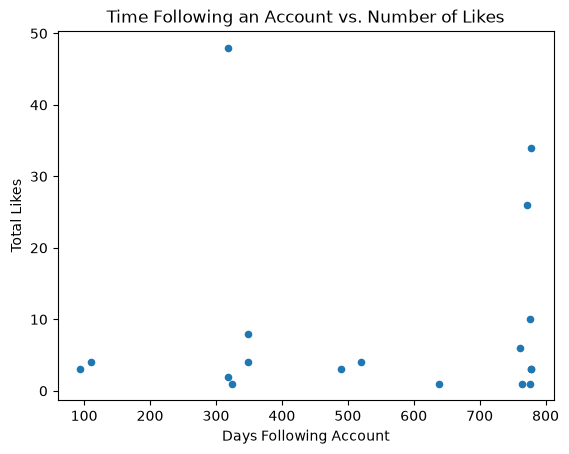

In [105]:
analysis_df.plot(
    kind='scatter',
    x='days_following',
    y='total_likes',
    title='Time Following an Account vs. Number of Likes',
    xlabel='Days Following Account',
    ylabel='Total Likes'
)

In [108]:
most_liked = analysis_df.loc[analysis_df['total_likes'].idxmax()]
longest_followed = analysis_df.loc[analysis_df['days_following'].idxmax()]

print("Most liked account:", most_liked['OwnerUsername'])
print("Longest followed account:", longest_followed['OwnerUsername'])
print("Same account:", most_liked['OwnerUsername'] == longest_followed['OwnerUsername'])

Most liked account: _pizzabacon
Longest followed account: _.sydneeallen
Same account: False


My hypothesis was not supported by my data. The account I have liked the most, pizzabacon, is different from the account I have followed the longest, _.sydneeallen, or any accounts followed shortly before that. This suggests that following an account for a longer amount of time does not necessarily mean I have liked the most posts from that account. However, it is important to note _pizzabacon is an outlier. This data only represents my own Instagram activity and only includes accounts I currently follow. Likes may not completely represent how much I like or interact with an account. I feel like some of my limitations was actually my small pool of data. I don't follow that many people so I can't see the full range of my likes. A next step would be to look at other types of social media activity and compare the results. I could also look at whether the same patterns appear across different platforms.
